In [2]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "..")

In [3]:
inside_folder = "data_from_wastewater_paper/pop8_comps"
inside_suffix = "_comps.csv"
own_suffix = "_comps_damping_compact_version.csv"
baseline_folder = "../output/baseline_contacts_2026-10-12"
factor_folders = {"own (factor 1)": baseline_folder,
                  "own (factor 2.2)": "../output/baseline_contacts_2026-10-18_100_2.2",
                  "own (factor from ABM Paper)": "../output/baseline_contacts_2026-10-21_100_1596_1"}
                  #"own (factor 2.2)": "output/baseline_contacts_2026-10-17_only_25_2.2"}

columns = ["S", "E", "Ins", "Isy", "Isev", "Icri", "R", "D", "prevalence"]
titles = {"prevalence": "Ins + Isy + Isev + Icri"}
colors = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple"]
observed_prevalence = np.array([329, 2350, 6136, 6279, 4679, 3357, 2421, 1757])

In [4]:
def read_daily(file):
    comps = pd.read_csv(file, sep=r"\s+")
    comps = comps.loc[:, ~comps.columns.str.startswith("Unnamed")]
    comps["prevalence"] = comps[["Ins", "Isy", "Isev", "Icri"]].sum(axis=1)
    comps["day"] = np.floor(comps["t"] / 24).astype(int)
    return comps.groupby("day")[columns].mean()

def load_setups(setup_files, particles):
    available = [p for p in particles
                 if all(os.path.exists(os.path.join(folder, f"{p}{suffix}")) for folder, suffix in setup_files.values())]
    setups = {name: [read_daily(os.path.join(folder, f"{p}{suffix}")) for p in available]
              for name, (folder, suffix) in setup_files.items()}
    number_of_days = min(len(daily) for runs in setups.values() for daily in runs)
    setups = {name: [daily.iloc[:number_of_days] for daily in runs] for name, runs in setups.items()}
    return setups, available


In [5]:
def plot_compartments(setups, show_single_runs):
    figure, axes = plt.subplots(3, 3, figsize=(15, 11), sharex=True)
    for axis, column in zip(axes.flat, columns):
        for color, (name, runs) in zip(colors, setups.items()):
            values = np.array([daily[column].to_numpy() for daily in runs])
            days = np.arange(values.shape[1])
            if show_single_runs:
                axis.plot(days, values.T, color=color, alpha=0.08, linewidth=0.6)
            axis.fill_between(days, np.percentile(values, 5, axis=0), np.percentile(values, 95, axis=0),
                              color=color, alpha=0.2)
            axis.plot(days, np.median(values, axis=0), color=color, label=name)
        axis.set_title(titles.get(column, column))
    for axis in axes[-1]:
        axis.set_xlabel("Day")
    axes.flat[0].legend()
    figure.suptitle("Median and 5-95 % over all particles")
    figure.tight_layout()
    return figure

def summary_table(setups):
    # median over all particles
    def metrics(daily):
        prevalence = daily["prevalence"].to_numpy()
        weekly = prevalence[:56].reshape(8, 7).mean(axis=1)
        return {"peak": prevalence.max(), "peak_day": prevalence.argmax(),
                "cumulative": daily["S"].iloc[0] - daily["S"].iloc[-1],
                "distance": np.linalg.norm(weekly - observed_prevalence)}
    tables = {name: pd.DataFrame([metrics(daily) for daily in runs]) for name, runs in setups.items()}
    inside = tables["inside"]
    rows = []
    for name, table in tables.items():
        rows.append({"setup": name,
                     "contento distance": table["distance"].median(),
                     "peak": table["peak"].median(),
                     "peak / inside": (table["peak"] / inside["peak"]).median(),
                     "cumulative / inside": (table["cumulative"] / inside["cumulative"]).median(),
                     "peak day - inside": (table["peak_day"] - inside["peak_day"]).median()})
    return pd.DataFrame(rows).set_index("setup").round(2)

                             contento distance      peak  peak / inside  cumulative / inside  peak day - inside
setup                                                                                                          
inside                                 3634.20   7889.46           1.00                 1.00                0.0
own (factor 1)                         9772.19   1370.48           0.17                 0.11                0.0
own (factor 2.2)                       4647.17   9918.77           1.25                 1.06                1.0
own (factor from ABM Paper)            7673.53  10991.42           1.33                 1.25                1.0


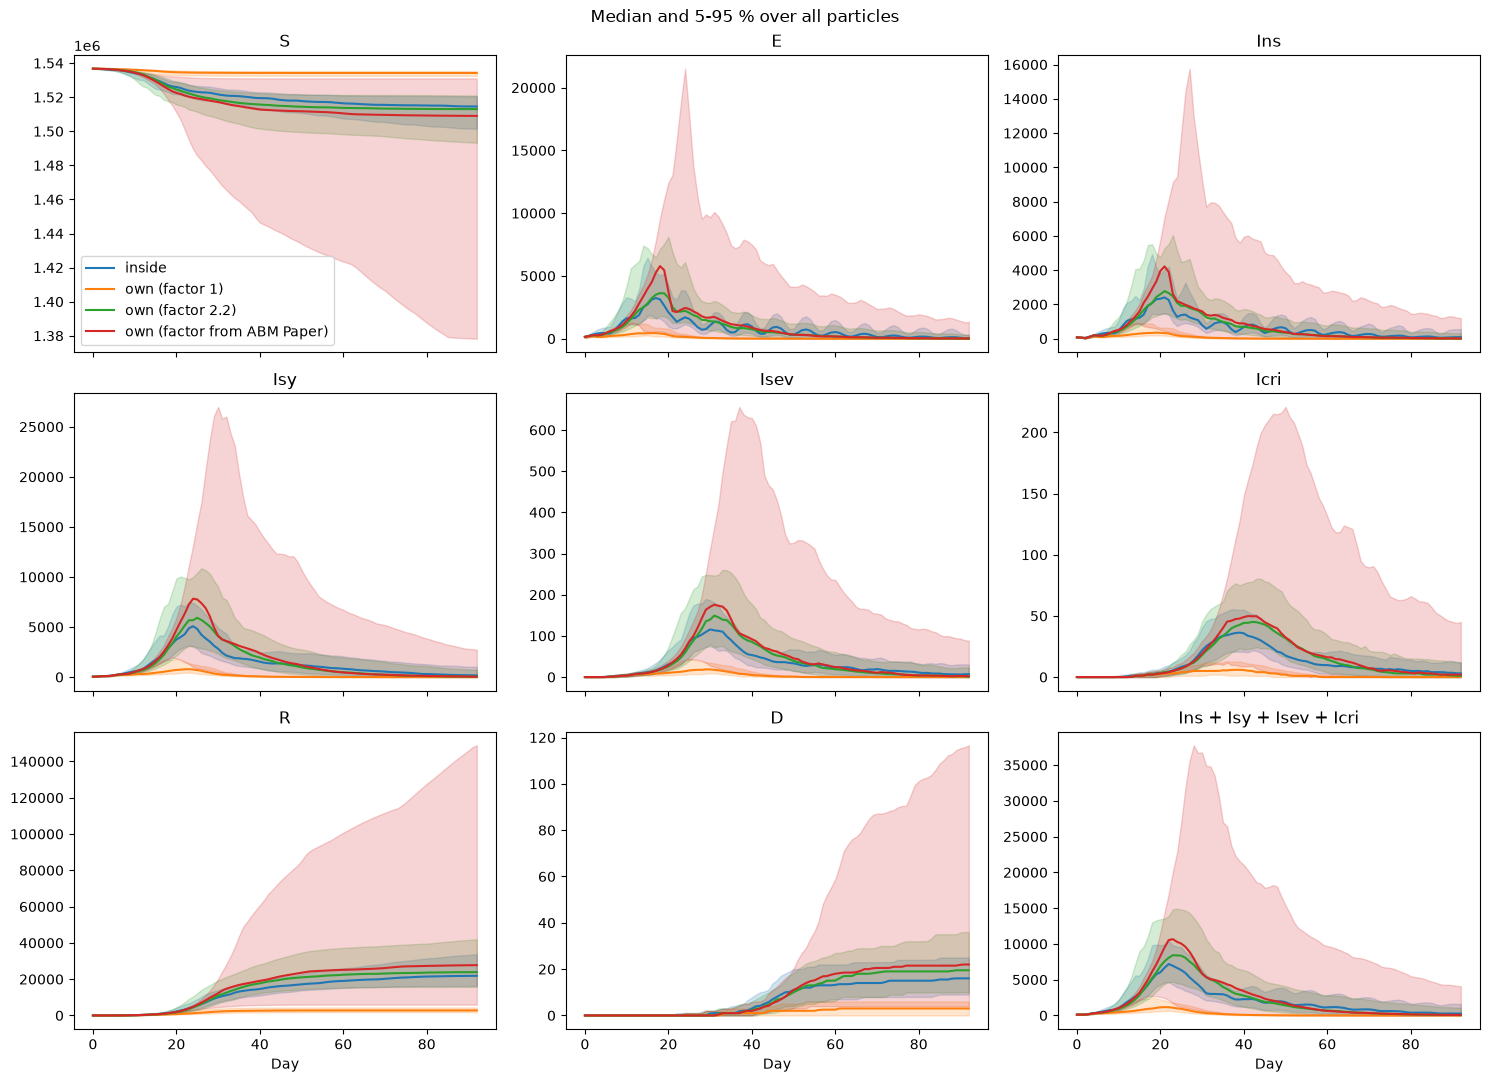

In [6]:
setup_files = {"inside": (inside_folder, inside_suffix)}
setup_files.update({name: (folder, own_suffix) for name, folder in factor_folders.items()})
setups, particles = load_setups(setup_files, range(1, 101))
figure = plot_compartments(setups, show_single_runs=False)
print(summary_table(setups).to_string())

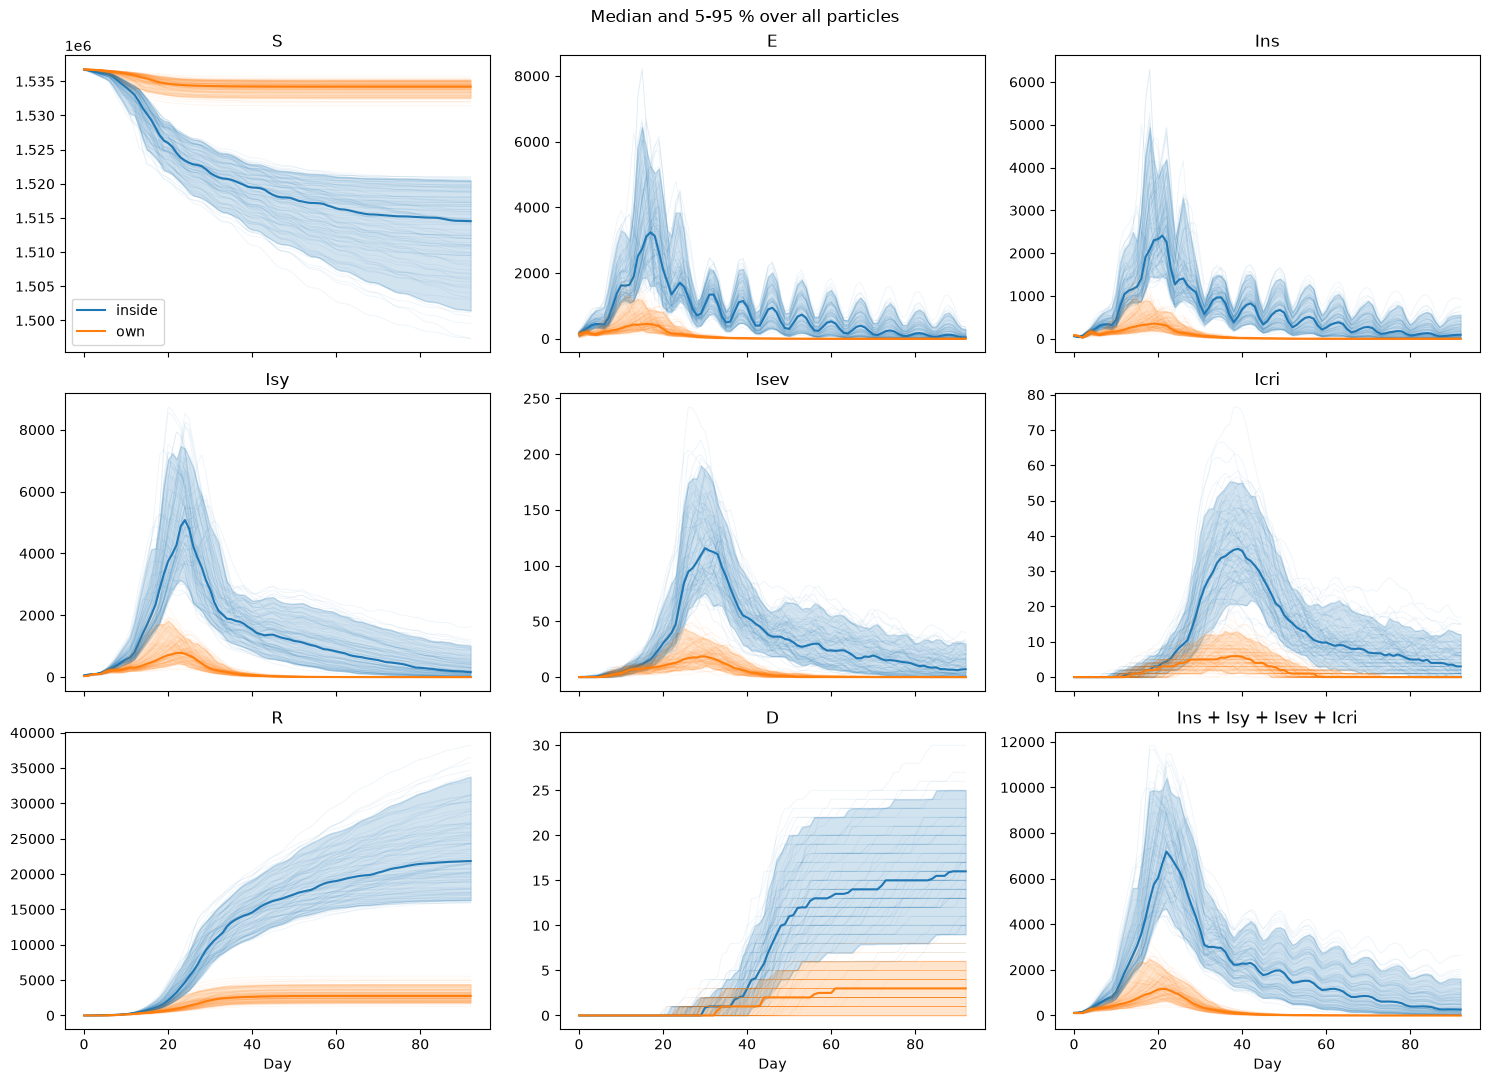

In [7]:
setup_files = {"inside": (inside_folder, inside_suffix), "own": (baseline_folder, own_suffix)}
setups, particles = load_setups(setup_files, range(1, 101))
figure = plot_compartments(setups, show_single_runs=True)
plt.show()